In [1]:
import pandas as pd
from scripts.extract_dataset import group_by_last_author
from scripts.iclr_analysis import compute_text_embeddings_SBERT, compute_tsne
from scripts.update_dataset import update
import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv
import os

c:\Users\angel\anaconda3\envs\iclr\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Importing the 2026 ICLR OpenReview Dataset

In [2]:
iclr2026v1 = pd.read_parquet("data/iclr26v1.parquet")
iclr2026v1.head()

,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels
0,2017,B1-Hhnslg,Prototypical Networks for Few-shot Learning,A recent approach to few-shot classification c...,"Jake Snell, Kevin Swersky, Richard Zemel",,Reject,"[6, 4, 5]","[deep learning, transfer learning]",transfer learning
1,2017,B1-q5Pqxl,Machine Comprehension Using Match-LSTM and Ans...,Machine comprehension of text is an important ...,"Shuohang Wang, Jing Jiang",,Accept (Poster),"[6, 6, 7]","[natural language processing, deep learning]",language models
2,2017,B16Jem9xe,Learning in Implicit Generative Models,Generative adversarial networks (GANs) provide...,"Shakir Mohamed, Balaji Lakshminarayanan",,Invite to Workshop Track,"[8, 7, 6]",[unsupervised learning],unlabeled
3,2017,B16dGcqlx,Third Person Imitation Learning,Reinforcement learning (RL) makes it possible ...,"Bradly C Stadie, Pieter Abbeel, Ilya Sutskever",,Accept (Poster),"[6, 5, 6]",[],unlabeled
4,2017,B184E5qee,Improving Neural Language Models with a Contin...,We propose an extension to neural network lang...,"Edouard Grave, Armand Joulin, Nicolas Usunier",,Accept (Poster),"[7, 9, 5]",[natural language processing],language models


For each row we have the `year`, `id`, `title`, `abstract`, `authors`, `author_ids`, `decision`, `scores`, `keywords`, and `labels`. For some papers, the authors may be listed as `Anonymous` or as an empty string with no scores or decisions. We want to see if we can update these papers, especially since the final decisions for papers to the ICLR 2026 Conference was in Jan 25 2026 (https://iclr.cc/Conferences/2026/CallForPapers).

In [3]:
print(f"How many papers with 'Anonymous' as the author: {len(iclr2026v1[iclr2026v1["authors"] == "Anonymous"])}")
print(f"How many papers who do not list an author: {len(iclr2026v1[iclr2026v1["authors"] == ""])}")
print(f"What is the minimum year of a paper with 'Anonymous': {iclr2026v1.loc[iclr2026v1["authors"] == "Anonymous", "year"].min()}")
print(f"What is the maximum year of a paper with 'Anonymous': {iclr2026v1.loc[iclr2026v1["authors"] == "Anonymous", "year"].max()}")
print(f"What is the minimum year of a paper with an empty string: {iclr2026v1.loc[iclr2026v1["authors"] == "", "year"].min()}")
print(f"What is the maximum year of a paper with 'Anonymous': {iclr2026v1.loc[iclr2026v1["authors"] == "", "year"].max()}")


How many papers with 'Anonymous' as the author: 43
How many papers who do not list an author: 19673
What is the minimum year of a paper with 'Anonymous': 2018
What is the maximum year of a paper with 'Anonymous': 2021
What is the minimum year of a paper with an empty string: 2026
What is the maximum year of a paper with 'Anonymous': 2026


This indicates that the papers whose list authors of empty string are part of the double-blind process in the 2026 ICLR Submissions. The authors with the name "Anonymous" may have been submitted as "Anonymous" and then they withdrew their work before it could be properly reviewed, thus ICLR kept their name as "Anonymous". 

While we have the code to update `iclr2026v1` to `iclr2026v2`, due to rate limits accessing ICLR API, updating the dataset takes a long time. For Milestone 2, we will use the `iclr2025v2` dataset, but we will use the updated dataset in our final project. We will also exclude papers whose authors are `Anonymous`. 

In [14]:
iclr2025v2 = pd.read_parquet("data/iclr25v2.parquet")
iclr2025v2 = iclr2025v2[iclr2025v2["authors"] != "Anonymous"]
print(f"How many papers with 'Anonymous' as the author: {len((iclr2025v2.loc[iclr2025v2["authors"] == "Anonymous"]))}")
print(f"How many papers who do not list an author: {len(iclr2025v2[iclr2025v2["authors"] == ""])}")

How many papers with 'Anonymous' as the author: 0
How many papers who do not list an author: 0


In [15]:
iclr2025v2.head()

,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels
0,2017,B1-Hhnslg,Prototypical Networks for Few-shot Learning,A recent approach to few-shot classification c...,"Jake Snell, Kevin Swersky, Richard Zemel",,Reject,"[6, 4, 5]","[deep learning, transfer learning]",transfer learning
1,2017,B1-q5Pqxl,Machine Comprehension Using Match-LSTM and Ans...,Machine comprehension of text is an important ...,"Shuohang Wang, Jing Jiang",,Accept (Poster),"[6, 6, 7]","[natural language processing, deep learning]",language models
2,2017,B16Jem9xe,Learning in Implicit Generative Models,Generative adversarial networks (GANs) provide...,"Shakir Mohamed, Balaji Lakshminarayanan",,Invite to Workshop Track,"[8, 7, 6]",[unsupervised learning],unlabeled
3,2017,B16dGcqlx,Third Person Imitation Learning,Reinforcement learning (RL) makes it possible ...,"Bradly C Stadie, Pieter Abbeel, Ilya Sutskever",,Accept (Poster),"[6, 5, 6]",[],unlabeled
4,2017,B184E5qee,Improving Neural Language Models with a Contin...,We propose an extension to neural network lang...,"Edouard Grave, Armand Joulin, Nicolas Usunier",,Accept (Poster),"[7, 9, 5]",[natural language processing],language models


# Group Papers by Principal Investigator (Last Listed Author)

Here we are assuming that the last author listed in `authors` is the Principal Investigators (PIs). We want to analyze the PIs because they have more publications than a new researcher and have better intuition on whether to stay in a research topic or to branch out.

In [17]:
last_author_df = group_by_last_author(iclr2025v2)
last_author_df.sort_values("num_papers", ascending=False).head()

,last_author,ids,titles,abstracts,collaborators,decisions,scores,keywords,labels,num_papers
9708,Sergey Levine,"[Bkul3t9ee, H1kjdOYlx, Hyq4yhile, SJ3rcZcxl, S...",[Unsupervised Perceptual Rewards for Imitation...,[Reward function design and exploration time a...,"[[Pierre Sermanet, Kelvin Xu], [Jacob Andreas,...","[Invite to Workshop Track, Invite to Workshop ...","[[6, 6, 4], [4, 3, 5], [6, 6, 7], [7, 7, 7, 8]...","[[computer vision, deep learning, unsupervised...","[transfer learning, transfer learning, transfe...",116
2116,Dacheng Tao,"[B1x6BTEKwr, r1xpF0VYDS, rkgg6xBYDH, rygRP2VYw...",[Piecewise linear activations substantially sh...,[Understanding the loss surface of a neural ne...,"[[Fengxiang He, Bohan Wang], [Kaining Zhang, M...","[Accept (Poster), Reject, Accept (Poster), Rej...","[[3, 6, 6], [3, 6, 6], [6, 6, 6], [3, 6, 3], [...","[[neural network, nonlinear activation, loss s...","[unlabeled, unlabeled, RNNs, unlabeled, few-sh...",88
12601,Yoshua Bengio,"[BJ0Ee8cxx, BJC_jUqxe, BJwFrvOeg, BkSmc8qll, S...","[Hierarchical Memory Networks, A STRUCTURED SE...",[Memory networks are neural networks with an e...,"[[Sarath Chandar, Sungjin Ahn, Hugo Larochelle...","[Reject, Accept (Poster), Reject, Reject, Acce...","[[5, 5, 4], [8, 5, 6], [6, 6, 6], [6, 7, 4], [...","[[deep learning, natural language processing],...","[language models, language models, language mo...",85
5618,Junchi Yan,"[rJlhYa4FPB, KLH36ELmwIB, drEe_dOHE_, gMRmCMoO...",[An Information Theoretic Perspective on Disen...,[Existing works on disentangled representation...,"[[Xiaojiang Yang, Wendong Bi, Yu Cheng], [Xian...","[Withdrawn, Accept (Poster), Withdrawn, Withdr...","[[3, 1, 1], [6, 6, 8, 6], [3, 4, 5, 6], [5, 5,...","[[], [neural architecture search, darts stabil...","[unlabeled, neural architecture search, GANs, ...",84
10913,Tom Goldstein,"[HkmaTz-0W, Skj8Kag0Z, BJgFcj0qKX, BJlr0j0ctX,...",[Visualizing the Loss Landscape of Neural Nets...,[Neural network training relies on our ability...,"[[Hao Li, Zheng Xu, Gavin Taylor], [Abhay Yada...","[Invite to Workshop Track, Accept (Poster), Wi...","[[5, 4, 5], [7, 9, 4], [5, 3, 5], [7, 4, 2], [...","[[visualization, loss surface, flatness, sharp...","[unlabeled, optimization, object detection, ad...",80


# Initial Analysis

## Visualization: Complementary Cumulative Distribution Function (CCDF)

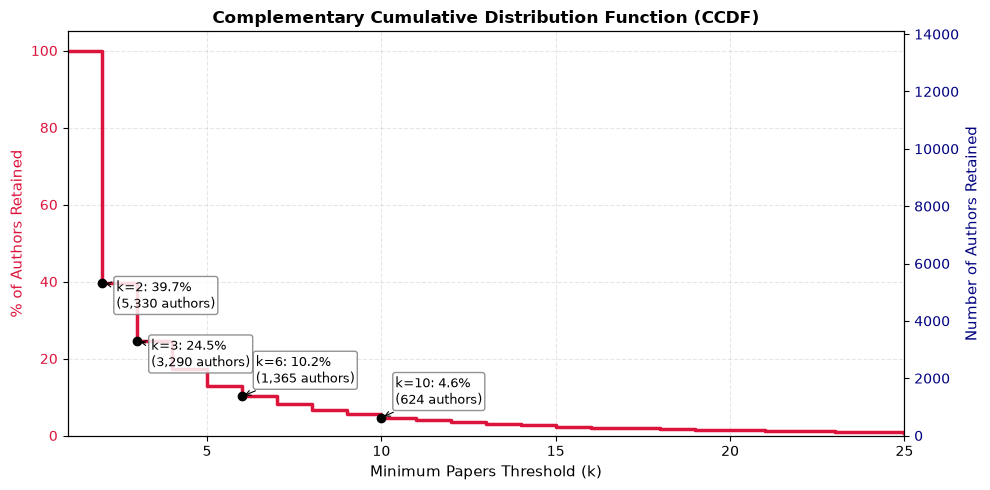

In [19]:
paper_counts = last_author_df["num_papers"].values
n_total = len(paper_counts)

k_values = np.arange(1, 26)
retention_pct = np.array([(paper_counts >= k).mean() * 100 for k in k_values])

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.step(k_values, retention_pct, where="post", color="crimson", linewidth=2.5)
ax1.set_xlabel("Minimum Papers Threshold (k)", fontsize=11)
ax1.set_ylabel("% of Authors Retained", color="crimson", fontsize=11)
ax1.tick_params(axis="y", labelcolor="crimson")
ax1.set_xlim(1, 25)
ax1.set_ylim(0, 105)
ax1.grid(True, linestyle="--", alpha=0.3)


ax2 = ax1.twinx()
ax2.set_ylabel("Number of Authors Retained", color="navy", fontsize=11)
ax2.set_ylim(0, n_total * 1.05)
ax2.tick_params(axis="y", labelcolor="navy")

for k in [2, 3, 6, 10]:
    pct = (paper_counts >= k).mean() * 100
    cnt = (paper_counts >= k).sum()
    ax1.plot(k, pct, marker="o", markersize=6, color="black", zorder=5)
    ax1.annotate(
        f"k={k}: {pct:.1f}%\n({cnt:,} authors)",
        (k, pct),
        textcoords="offset points",
        xytext=(10, -18 if k in [2, 3] else 10),
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="gray", alpha=0.85),
        arrowprops=dict(arrowstyle="->", lw=0.8, color="black")
    )

plt.title("Complementary Cumulative Distribution Function (CCDF)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

For this inital analysis, we have decided to look at last listed authors who are part of 5 papers or more. This is because we want to study researchers who published more than 1 paper. These are the authors who decided to stay within a field and/or to change fields.

In [22]:
threshold = 5
df = last_author_df[(last_author_df["num_papers"] >= threshold) & (last_author_df["last_author"] != "Anonymous")].reset_index(drop=True)
df.head()

,last_author,ids,titles,abstracts,collaborators,decisions,scores,keywords,labels,num_papers
0,Aaron Courville,"[B1ElR4cgg, BJ9fZNqle, BJKYvt5lg, SyxeqhP9ll, ...","[Adversarially Learned Inference, Multi-modal ...",[We introduce the adversarially learned infere...,"[[Vincent Dumoulin, Ishmael Belghazi, Ben Pool...","[Accept (Poster), Reject, Accept (Poster), Acc...","[[7, 8, 7], [3, 4, 4], [7, 7, 6], [7, 8, 8], [...","[[computer vision, deep learning, unsupervised...","[semi-supervised learning, language models, un...",42
1,Abhinav Gupta,"[SkzeJ3A9F7, SyMWn05F7, rygk9oA9Ym, ryl8-3AcFX...",[Beyond Games: Bringing Exploration to Robots ...,[Exploration has been a long standing problem ...,"[[Deepak Pathak, Dhiraj Gandhi], [Tao Chen, Sa...","[Reject, Accept (Poster), Reject, Accept (Post...","[[3, 3, 5], [3, 7, 7], [6, 3, 5], [6, 6, 6], [...","[[exploration, curiosity, manipulation], [expl...","[unlabeled, RL, unlabeled, RL, RL, RL, unlabel...",10
2,Abhinav Shrivastava,"[HkgxW0EYDS, r1x1kJHKDH, rkgrbTNtDr, L2LEB4vd9...",[Scalable Model Compression by Entropy Penaliz...,[We describe a simple and general neural netwo...,"[[Deniz Oktay, Johannes Ballé, Saurabh Singh],...","[Accept (Poster), Withdrawn, Reject, Reject, A...","[[6, 8, 6], [3, 3, 3], [3, 3, 3], [7, 6, 5, 5]...","[[deep learning, model compression, computer v...","[compression, unlabeled, GANs, transformers, u...",12
3,Abhishek Gupta,"[1P8eOmWgdk, LQ6LQ8f4y8, dsw5CNOVn1, jNR6s6OSB...",[Model-free Reinforcement Learning that Transf...,[Favorable reinforcement learning (RL) algorit...,"[[Boyuan Chen, Chuning Zhu, Pulkit Agrawal, Ka...","[Reject, Accept (poster), Withdrawn, Accept (o...","[[8, 5, 3, 5], [6, 6, 6, 5], [3, 5, 6, 3], [8,...","[[reinforcement learning, model-free, transfer...","[RL, imitation learning, unlabeled, unlabeled,...",5
4,Abhradeep Guha Thakurta,"[sXNVFBc-0aP, Ab8hkaJSJI, IskSBCo0-0, xHmCdSAr...",[Public Data-Assisted Mirror Descent for Priva...,"[In this paper, we revisit the problem of effe...","[[Ehsan Amid, Arun Ganesh, Rajiv Mathews, Swar...","[Reject, Reject, Reject, Accept (poster), Acce...","[[8, 6, 5], [5, 6, 6, 5], [5, 6, 5], [8, 8, 1]...","[[differential privacy, public data, mirror de...","[privacy, privacy, privacy, optimization, priv...",6


## Distribution of Papers per Author

<Axes: title={'center': 'Number of Authors vs. Number of Papers (No log)'}, xlabel='Number of Papers', ylabel='Number of Authors'>

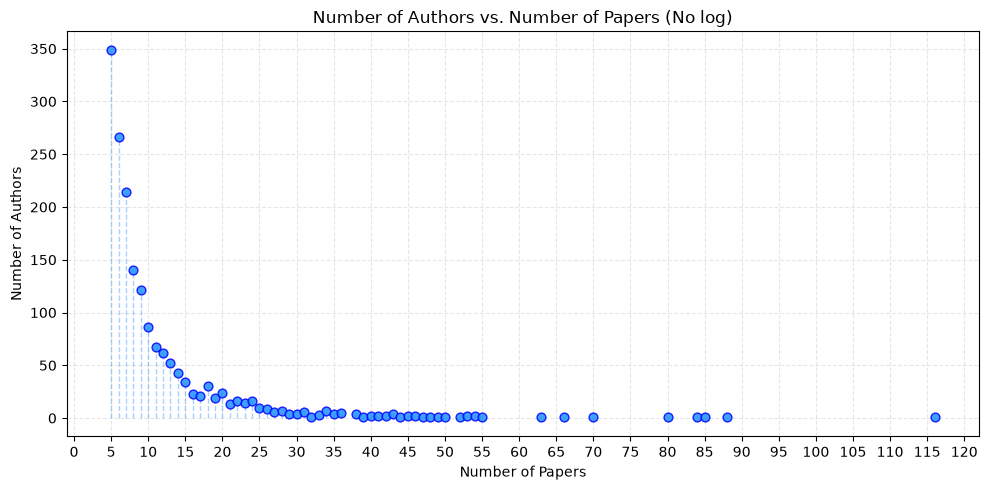

In [23]:
paper_freq = df["num_papers"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.vlines(
    x=paper_freq.index,
    ymin=0,
    ymax=paper_freq.values,
    color="dodgerblue",
    linestyle="--",
    alpha=0.4,
    linewidth=1,
)
plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xticks(range(0, 125, 5))
plt.xlim(left=-1, right=122)
plt.title("Number of Authors vs. Number of Papers (No log)")
plt.xlabel("Number of Papers")
plt.ylabel("Number of Authors")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.gca()

<Axes: title={'center': 'Number of Authors vs. Number of Papers (Log-Log Scale)'}, xlabel='Number of Papers (log scale)', ylabel='Number of Authors (log scale)'>

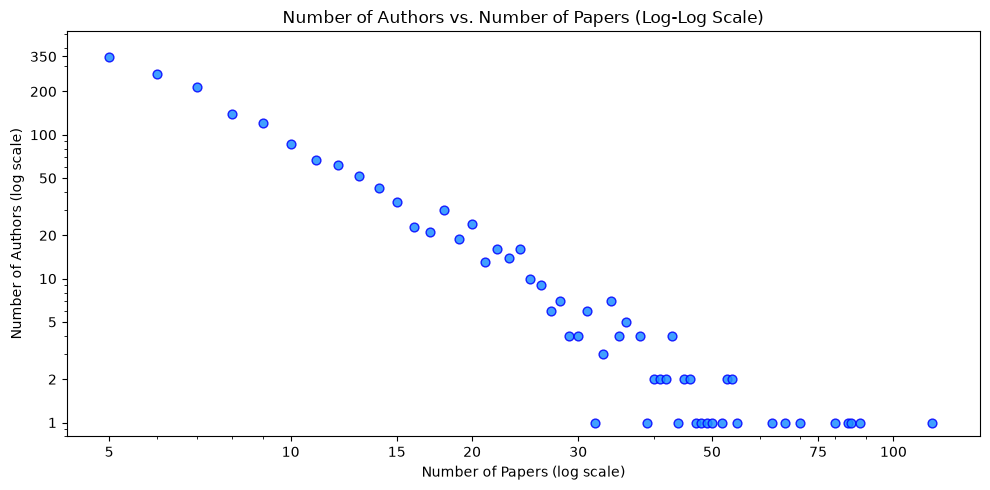

In [24]:
plt.figure(figsize=(10, 5))

plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xscale("log")
plt.yscale("log")

plt.xlim(left=threshold * 0.85, right=paper_freq.index.max() * 1.2)
plt.ylim(bottom=0.8, top=paper_freq.values.max() * 1.5)

x_ticks = [5, 10, 15, 20, 30, 50, 75, 100]
plt.xticks(x_ticks, x_ticks)

y_ticks = [1, 2, 5, 10, 20, 50, 100, 200, 350]
plt.yticks(y_ticks, y_ticks)

plt.title("Number of Authors vs. Number of Papers (Log-Log Scale)")
plt.xlabel("Number of Papers (log scale)")
plt.ylabel("Number of Authors (log scale)")
plt.tight_layout()
plt.gca()

# Paper Representation: Recreating the Embeddings

The authors of the original paper used multiple models to convert the abstracts into representations. One approach was to use SBERT, which was shown to have the highest performance. The authors do not provide their weights, but fortunately they provide the code to recreate their embeddings.

The main pipeline from the paper is to first use SBERT then to use t-SNE to map the SBERT's embeddings into a 2D space. 

In [ ]:
# Run the code below for the first time. It downloads the SBERT embeddings and output it in `output_dir`.
#
# output_path = "..."
# autotokenizer_path = "..." # Can be extracted from download_tokenizer() from script.iclr_analysis
# embedding_cls, embedding_sep, embedding_av = compute_text_embeddings_SBERT(
#     iclr2025v2["abstract"].tolist(),
#     output_path=output_path
# )

SBERT_embeddings_path = "data\embeddings_sbert"
_, _, embedding_av = compute_text_embeddings_SBERT(
    embeddings_path = SBERT_embeddings_path
)

<>:10: SyntaxWarning: invalid escape sequence '\e'
<>:10: SyntaxWarning: invalid escape sequence '\e'
C:\Users\angel\AppData\Local\Temp\ipykernel_10980\211460965.py:10: SyntaxWarning: invalid escape sequence '\e'
  SBERT_embeddings_path = "data\embeddings_sbert"


In [ ]:
tsne_av = compute_tsne(embeddings=embedding_av)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_jobs=-1, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 59.39 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.57 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.42 seconds
===> Running optimization with exaggeration=12.00, lr=4658.83 for 250 iterations...
Iteration   50, KL divergence 6.3887, 50 iterations in 3.4660 sec
Iteration  100, KL divergence 6.4941, 50 iterations in 3.9292 sec
Iteration  150, KL divergence 6.4934, 50 iterations in 3.8705 sec
Iteration  200, KL divergence 6.4933, 50 iterations in 3.6934 sec
Iteration  250, KL divergence 6.4932, 50 iterations in 3.9677 sec
   --> Time elapsed: 18.93 seconds
===> Running optimization with exaggerati

The authors provided code to create the visualization below. Here, we have the top 18 authors in the ICLR dataset in terms of number of publications to ICLR. The gray area is the t-SNE mapping of our SBERT embeddings. The black dots represents a paper from the author and where it's located in the embedding space. The top number is the number of publications and the bottom number is overall acceptance rate.

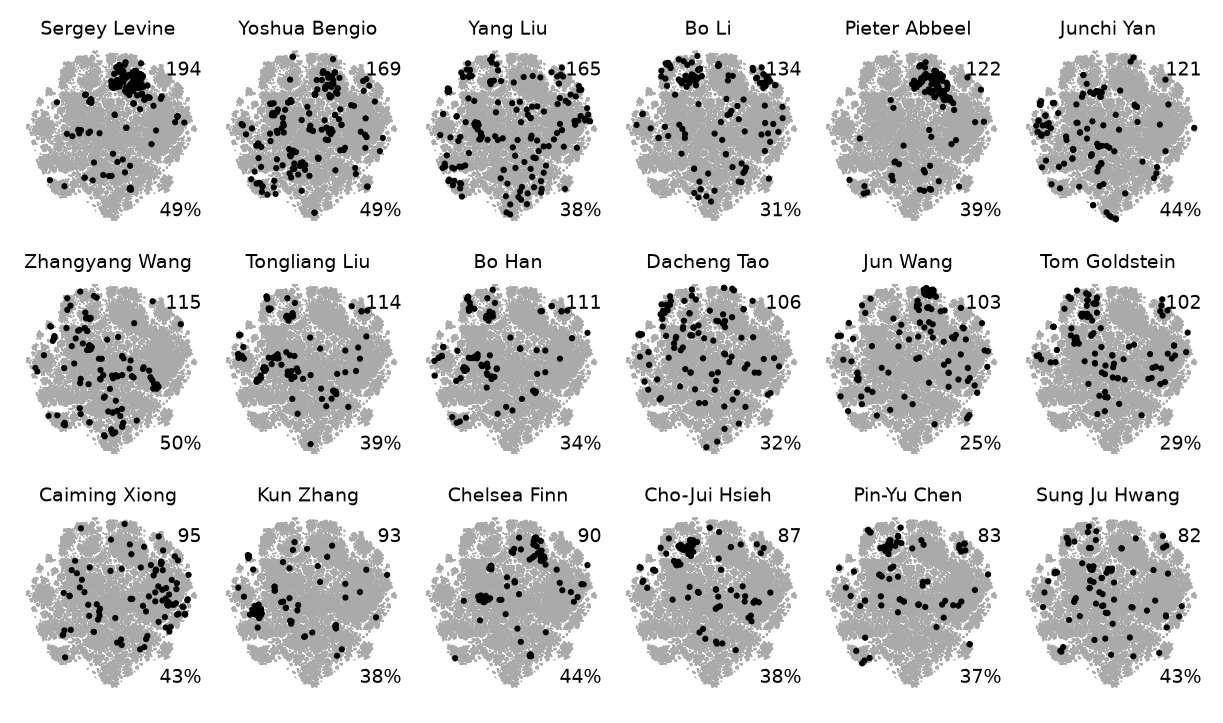

In [ ]:
# Strip and filter out empty or anonymous author strings
all_authors = [
    author.strip()
    for row in iclr2026v1.authors
    if row
    for author in row.split(', ')
    if author.strip() and author.strip() != "Anonymous"
]
authors, counts = np.unique(all_authors, return_counts=True)
ind = np.argsort(counts)[::-1]
top_authors = authors[ind]

fig_plot, axs = plt.subplots(nrows=3, ncols=6, figsize=(6.0, 3.5), layout='constrained')

for num, author in enumerate(top_authors[:18]):
    mask = [author in a.split(', ') for a in iclr2026v1.authors]
    
    axs.flat[num].axis('equal')
    axs.flat[num].scatter(*tsne_av.T, s=.5, ec='none', c='#aaaaaa', rasterized=True)
    axs.flat[num].scatter(*tsne_av[mask].T, s=5, ec='none', c='k', zorder=2)

    axs.flat[num].axis('off')
    axs.flat[num].set_title(f'{author}', fontsize=7, y=.92, x=.48)
    axs.flat[num].text(.99, .8, f'{np.sum(mask)}', ha='right', transform=axs.flat[num].transAxes, fontsize=7)
    
    accepted = np.array([d[:6]=='Accept' for d in iclr2026v1.decision])
    acceptance_rate = np.nanmean(accepted[mask]) * 100
    axs.flat[num].text(.99, .1, f'{acceptance_rate:.0f}%', fontsize=7, 
                       ha='right', transform=axs.flat[num].transAxes)
fig_plot
